# 함수

**이 노트북에서 할 일**

1. 할인 계산에 이름을 붙여 함수로 정의하고, 인자를 넣어 호출합니다.
2. 반환값, 함수 안의 이름, 기본값이 있는 매개변수를 출력으로 확인합니다.
3. 기본값을 빈 목록으로 둔 함수가 호출 사이에 목록을 함께 쓰는 장면을 보고, `None`으로 고칩니다.

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 모델 호출은 0번이고 비용은 들지 않습니다.
실행 시간은 1분 이내입니다.

1~3절과 같은 실습 폴더 `labs/part1/ch02-python`의 `.venv`를 커널로 고릅니다.
이전 커널의 변수는 쓰지 않으므로 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

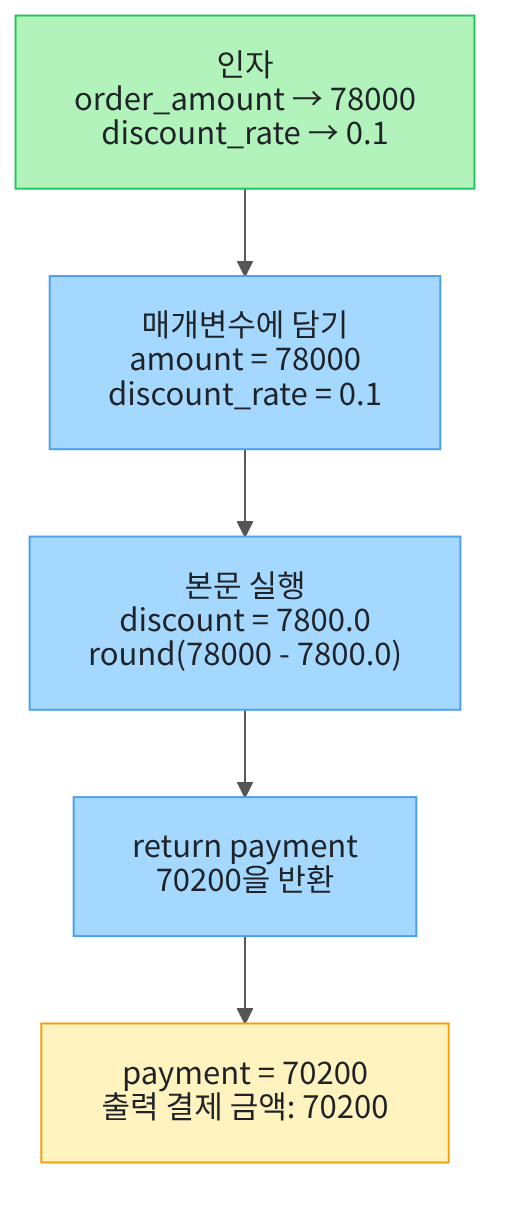

위에서 아래로 읽습니다. 초록 상자는 호출할 때 넣는 값이고, 파란 상자는 함수 안에서 실행되는 차례입니다.

값 78000과 0.1이 매개변수 amount와 discount_rate에 담깁니다. 본문이 할인액 7800.0을 계산하고, return 줄이 70200을 반환합니다.
맨 아래 노란 상자는 반환값에 붙인 이름 payment와 그 출력입니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 준비 셀은 3절에서 만든 주문 딕셔너리 `order`를 새 커널에 다시 저장합니다.
주문 네 건의 금액은 3절에서 27000을 추가한 뒤의 목록입니다. 할인율 0.1은 1·2절에서 쓴 회원 할인율입니다.

In [1]:
# 3절에서 만든 주문 한 건과 주문 네 건의 금액을 새 커널에 다시 저장합니다
order = {"order_id": "A102", "product_name": "무선 키보드", "amount": 78000, "shipping_fee": 0}
order_amounts = [18000, 42000, 65000, 27000]
# 1·2절에서 쓴 회원 할인율입니다
discount_rate = 0.1
order_amount = order["amount"]
print("주문 번호:", order["order_id"])
print("주문 금액:", order_amount)
print("주문 네 건의 금액:", order_amounts)
print("할인율:", discount_rate)

주문 번호: A102
주문 금액: 78000
주문 네 건의 금액: [18000, 42000, 65000, 27000]
할인율: 0.1


**결과 읽기** — 주문 번호 `A102`, 주문 금액 `78000`입니다. 주문 네 건의 금액은 `[18000, 42000, 65000, 27000]`, 할인율은 `0.1`입니다.
금액은 3절처럼 원 단위 정수입니다.

## 2. 함수 정의하기

함수(function)는 여러 줄의 처리에 이름을 붙여 두고, 필요할 때 그 이름으로 불러 실행하는 코드 묶음입니다.
가게에서 할인 계산 순서를 종이에 적고 「할인 계산」이라는 제목을 붙여 두는 것과 같습니다.
이 셀은 1절의 할인 계산 두 줄에 이름 `calculate_payment`를 붙입니다.

정의는 예약어 `def`로 시작합니다. 그 뒤에 함수 이름, 소괄호 안의 매개변수, 콜론 `:`을 차례로 적습니다.
매개변수(parameter)는 함수가 받을 값에 붙이는 이름입니다. 이 함수에는 `amount`와 `discount_rate` 두 개가 있습니다.
함수에 속한 줄은 `if` 아래 줄처럼 들여 씁니다.

마지막 줄 `return payment`는 계산한 값을 함수를 부른 곳으로 보냅니다.
내장 함수 `round()`는 숫자 하나를 받아 가장 가까운 정수를 반환합니다. 할인액이 실수라서 결제 금액을 원 단위 정수로 맞춥니다.

실행 전에 예상합니다. 정의만 하는 셀이라 아무것도 출력되지 않을 것입니다.

In [2]:
# 주문 금액과 할인율을 받아 할인한 결제 금액을 반환하는 함수를 정의합니다
def calculate_payment(amount, discount_rate):
    # 1절과 같은 순서로 할인액을 먼저 계산합니다
    discount = amount * discount_rate
    # round()로 소수점 없는 원 단위 금액을 만듭니다
    payment = round(amount - discount)
    return payment

**결과 읽기** — 예상대로 출력이 없습니다. 정의 셀은 함수 이름과 본문을 기억해 둘 뿐입니다.
본문의 계산 줄은 함수를 호출할 때 실행됩니다.

## 3. 함수 호출하기

호출(call)은 함수 이름 뒤에 소괄호를 붙여 함수를 실행하는 일입니다. 1절에서 `type(quantity)`로 내장 함수를 호출해 보았습니다.
Ch 1 2절에서 괄호 안에 건네는 값을 인자(argument)라고 했습니다. 인자는 적은 순서대로 매개변수에 담깁니다.
첫 인자 `order_amount`의 값 78000은 `amount`에, 둘째 인자의 값 0.1은 `discount_rate`에 담깁니다.

반환값(return value)은 함수가 `return` 줄로 보낸 값입니다. 대입 `payment = calculate_payment(...)`은 반환값에 이름 `payment`를 붙입니다.

실행 전에 예상합니다. 1절에서 계산한 결제 금액과 같은 70200이 나오고, 이번에는 소수점이 없을 것입니다.

In [3]:
# 3절 주문 금액과 할인율을 인자로 넣어 함수를 호출합니다
payment = calculate_payment(order_amount, discount_rate)
print("주문 금액:", order_amount)
print("할인율:", discount_rate)
print("결제 금액:", payment)

주문 금액: 78000
할인율: 0.1
결제 금액: 70200


**결과 읽기** — 주문 금액 `78000`, 할인율 `0.1`을 넣어 부른 결과, 결제 금액은 `70200`으로 예상과 같습니다.

1절에서는 같은 계산의 결과가 실수 70200.0이었습니다. 함수 안의 `round()`가 정수로 맞춰, 3절처럼 원 단위 정수가 나왔습니다.

## 4. 여러 주문에 같은 함수 쓰기

함수는 한 번 정의하면 인자만 바꿔 여러 번 부를 수 있습니다. 2절에서는 회원 여부 하나를 바꾸려고 같은 조건문을 한 번 더 적었습니다.
함수를 쓰면 계산 줄을 다시 적지 않고 이름만 부릅니다.

주문 네 건의 결제 금액을 3절에서 정한 모양대로 빈 목록에 모읍니다. 반복문 `for`가 금액을 하나 읽을 때마다 함수를 부릅니다.
반환값은 `append()`로 목록 끝에 추가합니다.

실행 전에 예상합니다. 금액마다 10%를 뺀 16200, 37800, 58500, 24300이 차례로 모일 것입니다.

In [4]:
# 주문 네 건마다 같은 함수를 불러 결제 금액을 빈 목록에 모읍니다
payments = []
for amount in order_amounts:
    # 반복할 때마다 목록의 금액 하나가 첫 인자로 들어갑니다
    order_payment = calculate_payment(amount, discount_rate)
    payments.append(order_payment)
print("주문 금액:", order_amounts)
print("결제 금액:", payments)

주문 금액: [18000, 42000, 65000, 27000]
결제 금액: [16200, 37800, 58500, 24300]


**결과 읽기** — 결제 금액은 `[16200, 37800, 58500, 24300]`으로 예상과 같습니다. 주문 금액 `[18000, 42000, 65000, 27000]`과 같은 순서입니다.
함수는 2번 소제목에서 한 번만 정의했고, 이 셀에서 네 번 불렀습니다.

## 5. return 줄이 없는 함수

함수 안에서 결과를 `print()`로 출력만 하고 `return` 줄을 적지 않으면 어떻게 될까요?
아래 셀은 `calculate_payment()`와 같은 계산을 하는 함수 `print_payment()`를 정의합니다. 마지막 줄만 `return` 대신 `print()`입니다.

실행 전에 예상합니다. 본문에 `print()` 줄이 있어도 정의만 하는 셀이라 출력은 없을 것입니다.

In [5]:
# 결제 금액을 화면에 출력만 하고 return 줄은 없는 함수를 정의합니다
def print_payment(amount, discount_rate):
    discount = amount * discount_rate
    payment = round(amount - discount)
    # 반환하지 않고 화면에만 보여 줍니다
    print("함수 안에서 출력한 결제 금액:", payment)

**결과 읽기** — 예상대로 출력이 없습니다. 본문의 `print()` 줄도 함수를 호출하기 전에는 실행되지 않았습니다.

이제 함수 `print_payment()`를 호출하고, 반환값을 이름 `result`에 받아 봅니다.
값 `None`은 Ch 1 3절에서 본, 값이 없음을 나타내는 값입니다.
값 `None`은 프로그램 안에 하나만 있습니다. 그래서 이름이 그 `None` 하나에 붙어 있는지 3절의 연산자 `is`로 검사합니다.

실행 전에 예상합니다. 함수 안의 출력 줄이 결제 금액 70200을 보여 주지만, 반환값은 없을 것입니다.

In [6]:
# 출력만 하는 함수를 호출하고, 반환값을 이름 result에 받습니다
result = print_payment(order_amount, discount_rate)
print("반환값:", result)
# 반환값이 None인지 연산자 is로 검사합니다
is_none = result is None
print("반환값이 None인가:", is_none)

함수 안에서 출력한 결제 금액: 70200
반환값: None
반환값이 None인가: True


**결과 읽기** — 첫 줄 `함수 안에서 출력한 결제 금액: 70200`은 함수 본문의 `print()`가 출력했습니다. 그러나 반환값은 `None`이고, 반환값이 None인가는 `True`입니다.

return 줄이 없는 함수를 부르자 반환값으로 `None`을 받았습니다. 화면에 보인 70200은 이름 `result`에 담기지 않았으므로 뒤 계산에 쓸 수 없습니다.
뒤에서 쓸 값은 `return` 줄로 반환합니다.

## 6. 함수 안의 이름과 밖의 이름

지역 변수(local variable)는 함수 안에서 만든 이름입니다. 함수 밖에 같은 글자의 이름이 있어도 서로 따로 저장됩니다.
두 방에 같은 이름표를 단 상자가 하나씩 있으면, 한 방의 상자에 넣은 물건이 다른 방 상자에는 들어가지 않는 것과 같습니다.
함수 `calculate_payment()`의 본문에서 만든 `discount`와 `payment`가 지역 변수입니다.

범위(scope)는 이름을 쓸 수 있는 코드 영역입니다. 아래 셀은 함수 밖에 `discount = 0`을 만든 뒤 함수를 부릅니다.

실행 전에 예상합니다. 함수 안에서 할인액을 계산해도, 함수 밖의 `discount`는 0 그대로일 것입니다.

In [7]:
# 함수 밖에 discount를 만든 뒤 함수를 부르고, 밖의 discount를 다시 읽습니다
discount = 0
payment = calculate_payment(order_amount, discount_rate)
print("함수가 반환한 결제 금액:", payment)
# 함수 안의 discount와 이름만 같은 함수 밖의 이름입니다
print("함수 밖 discount:", discount)

함수가 반환한 결제 금액: 70200
함수 밖 discount: 0


**결과 읽기** — 함수가 반환한 결제 금액은 `70200`이고, 함수 밖 discount는 `0`으로 예상과 같습니다.

결제 금액이 70200이므로 함수 안의 `discount`에는 78000 × 0.1인 7800.0이 담겼습니다. 그래도 함수 밖의 `discount`는 바뀌지 않았습니다.
두 이름은 글자만 같고 서로 다른 범위에 있습니다. 함수 안의 값을 밖에서 쓰려면 `return`으로 반환해 이름을 붙입니다.

## 7. 기본값이 있는 매개변수

기본값(default value)은 호출할 때 인자를 넣지 않으면 매개변수가 대신 쓰는 값입니다. 카페에서 크기를 말하지 않으면 보통 크기로 주는 것과 같습니다.
정의 줄에서 매개변수 이름 뒤에 `=`과 값을 적습니다.

아래 함수 `calculate_line_total()`은 단가와 수량을 곱해 주문 줄 금액을 반환합니다. 매개변수 `quantity=1`은 수량을 넣지 않으면 1개로 계산한다는 뜻입니다.

실행 전에 예상합니다. 정의 셀이므로 출력은 없을 것입니다.

In [8]:
# 단가와 수량을 곱해 주문 줄 금액을 반환합니다(수량을 넣지 않으면 1개)
def calculate_line_total(unit_price, quantity=1):
    line_total = unit_price * quantity
    return line_total

**결과 읽기** — 출력이 없습니다. 정의 셀은 함수 이름, 본문, 기본값 1을 기억해 둡니다.

3절의 주문 줄 튜플 `("무선 키보드", 2, 39000)`에서 단가 39000과 수량 2를 가져와 씁니다.
한 번은 수량을 인자로 넣고, 한 번은 수량을 빼고 호출합니다.

실행 전에 예상합니다. 수량 2를 넣으면 78000이고, 수량을 빼면 기본값 1을 써서 39000일 것입니다.

In [9]:
# 3절 주문 줄의 단가와 수량으로, 수량을 넣은 호출과 뺀 호출을 비교합니다
unit_price = 39000
quantity = 2
line_total_two = calculate_line_total(unit_price, quantity)
# 인자를 하나만 넣으면 quantity는 기본값 1을 씁니다
line_total_default = calculate_line_total(unit_price)
print("수량 2를 넣었을 때:", line_total_two)
print("수량을 뺐을 때:", line_total_default)

수량 2를 넣었을 때: 78000
수량을 뺐을 때: 39000


**결과 읽기** — 수량 2를 넣었을 때 `78000`, 수량을 뺐을 때 `39000`으로 예상과 같습니다.

둘째 호출은 인자를 하나만 넣었습니다. 그래서 매개변수 `quantity`가 기본값 1을 썼습니다.
9번 Before에서는 기본값 자리에 숫자 대신 빈 목록을 둡니다.

## 8. 값 바꿔 보기 — 할인율 하나만 바꾸기

함수를 다시 정의하지 않고 인자 하나만 바꿔 부릅니다. 주문 금액 78000은 그대로 두고, 할인율만 0.1에서 0.2로 바꿉니다.

실행 전에 예상합니다. 할인액이 15600이 되어 결제 금액은 62400일 것입니다.

In [10]:
# 주문 금액은 그대로 두고 할인율만 0.2로 바꿔 같은 함수를 부릅니다
new_discount_rate = 0.2
new_payment = calculate_payment(order_amount, new_discount_rate)
print("원래 할인율:", discount_rate)
print("원래 결제 금액:", payment)
print("바꾼 할인율:", new_discount_rate)
print("바꾼 결제 금액:", new_payment)

원래 할인율: 0.1
원래 결제 금액: 70200
바꾼 할인율: 0.2
바꾼 결제 금액: 62400


**결과 읽기** — 바꾼 할인율 `0.2`에서 결제 금액은 `62400`으로 예상과 같습니다. 원래 할인율 `0.1`의 결제 금액 `70200`보다 7800원 적습니다.

바꾼 값은 할인율 하나뿐이고, 함수 정의는 그대로 두었습니다. 그래서 결제 금액의 차이는 할인율에서 나왔습니다.

## 9. Before — 기본값을 빈 목록으로 두기

주문마다 태그(tag) 목록을 만듭니다. 태그는 주문에 붙이는 짧은 표시입니다. 택배 상자에 「신규」나 「배송」 꼬리표를 다는 것과 같습니다.

함수 `add_tag_before()`는 태그 하나를 받아 태그 목록 끝에 추가하고, 그 목록을 반환합니다.
목록을 넣지 않으면 기본값 빈 목록 `[]`을 씁니다. 7번 소제목의 `quantity=1`과 같은 모양입니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [11]:
# 태그 하나를 목록 끝에 추가해 반환합니다(목록을 넣지 않으면 기본값 빈 목록)
def add_tag_before(tag, tags=[]):
    tags.append(tag)
    return tags

**결과 읽기** — 출력이 없습니다. 이번 정의는 기본값 자리에 숫자 대신 빈 목록을 두었습니다.

첫 주문에는 태그 신규를, 둘째 주문에는 태그 배송을 붙입니다. 두 번 모두 목록은 넣지 않고 기본값을 씁니다.

첫 호출 직후의 모습은 3절의 `copy()`로 따로 남겨 둡니다. 두 반환값이 같은 목록 하나인지는 3절의 연산자 `is`로 검사합니다.
이 셀은 한 번만 실행합니다. 여러 번 실행했다면 첫 셀부터 다시 실행합니다.

실행 전에 예상해 봅니다. 호출을 따로 했으니 첫 주문 태그는 신규 하나, 둘째 주문 태그는 배송 하나일까요?

In [12]:
# 목록을 넣지 않고 두 주문의 태그를 차례로 만듭니다
first_tags = add_tag_before("신규")
# 첫 호출 직후의 모습을 copy()로 따로 남겨 둡니다
first_snapshot = first_tags.copy()
second_tags = add_tag_before("배송")
is_same_list = first_tags is second_tags
print("첫 호출 직후 첫 주문 태그:", first_snapshot)
print("둘째 호출 뒤 첫 주문 태그:", first_tags)
print("둘째 주문 태그:", second_tags)
print("같은 목록인가:", is_same_list)

첫 호출 직후 첫 주문 태그: ['신규']
둘째 호출 뒤 첫 주문 태그: ['신규', '배송']
둘째 주문 태그: ['신규', '배송']
같은 목록인가: True


**결과 읽기** — 첫 호출 직후 첫 주문 태그는 `['신규']`였습니다. 그런데 둘째 호출 뒤 첫 주문 태그는 `['신규', '배송']`입니다. 둘째 주문 태그도 `['신규', '배송']`이고, 같은 목록인가는 `True`입니다.

오류는 나지 않았지만 두 주문의 태그가 한 목록에 섞였습니다. 두 호출은 목록을 새로 만들지 않았습니다. 같은 기본값 목록 하나에 `append()`로 태그를 추가했습니다.
3절 Before에서는 이름 두 개가 목록 하나에 붙었습니다. 이번에는 두 호출의 반환값이 목록 하나에 붙었습니다.

### 원리 더 알아보기 — 기본값 목록이 저장된 곳

Python 문서는 기본값을 함수를 정의할 때 한 번만 계산한다고 설명합니다. 만든 기본값은 함수에 붙어 저장됩니다.
아래 셀은 함수의 속성 `__defaults__`로 저장된 기본값을 읽습니다. 이 속성은 앞으로 쓰지 않으므로 지금은 출력만 읽습니다.

In [13]:
# 원리 더 알아보기: 함수에 저장된 기본값을 읽습니다
saved_defaults = add_tag_before.__defaults__
print("저장된 기본값:", saved_defaults)
# 저장된 기본값 목록과 첫 주문 태그가 같은 목록인지 봅니다
is_default_list = saved_defaults[0] is first_tags
print("기본값 목록과 첫 주문 태그가 같은 목록인가:", is_default_list)

저장된 기본값: (['신규', '배송'],)
기본값 목록과 첫 주문 태그가 같은 목록인가: True


**결과 읽기** — 저장된 기본값은 `(['신규', '배송'],)`입니다. 값 하나가 든 튜플이고, 그 값이 태그 두 개가 쌓인 목록입니다.
기본값 목록과 첫 주문 태그가 같은 목록인가는 `True`입니다. 두 호출이 함수에 저장된 목록 하나를 함께 썼습니다.

## 10. After — 기본값을 None으로 두기

기본값을 빈 목록 대신 `None`으로 둡니다. 본문에서 `tags is None`이 참이면 그때 새 빈 목록을 만듭니다.
본문의 줄은 호출할 때마다 실행됩니다. 그래서 목록을 넣지 않은 호출은 매번 새 목록을 받습니다.

Before 함수와 달라진 곳은 기본값 `[]`를 `None`으로 바꾼 것과, 새로 넣은 `if` 두 줄입니다. 함수 이름은 `add_tag()`로 바꿨습니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [14]:
# 목록을 넣지 않으면 호출할 때마다 새 빈 목록을 만들어 태그를 추가합니다
def add_tag(tag, tags=None):
    # 기본값 None은 목록을 받지 않았다는 표시입니다
    if tags is None:
        tags = []
    tags.append(tag)
    return tags

**결과 읽기** — 출력이 없습니다. 이번 정의는 기본값 자리에 빈 목록 대신 `None`을 두었습니다.

이번에는 Before와 같은 두 호출을 새 함수로 실행합니다. 태그 신규와 배송, 첫 호출 직후 복사, `is` 검사도 그대로입니다.
마지막에는 검사 줄 `assert`로 두 주문의 태그를 확인합니다.

실행 전에 예상합니다. 첫 주문 태그는 신규 하나, 둘째 주문 태그는 배송 하나이고, 같은 목록인가는 `False`일 것입니다.

In [15]:
# Before와 같은 두 호출을 새 함수로 실행합니다
first_tags = add_tag("신규")
first_snapshot = first_tags.copy()
second_tags = add_tag("배송")
is_same_list = first_tags is second_tags
print("첫 호출 직후 첫 주문 태그:", first_snapshot)
print("둘째 호출 뒤 첫 주문 태그:", first_tags)
print("둘째 주문 태그:", second_tags)
print("같은 목록인가:", is_same_list)
# 두 주문의 태그가 한 개씩 따로 있지 않으면 이 줄에서 멈춥니다
assert first_tags == ["신규"]
assert second_tags == ["배송"]

첫 호출 직후 첫 주문 태그: ['신규']
둘째 호출 뒤 첫 주문 태그: ['신규']
둘째 주문 태그: ['배송']
같은 목록인가: False


**결과 읽기** — 첫 호출 직후와 둘째 호출 뒤 모두 첫 주문 태그는 `['신규']`입니다. 둘째 주문 태그는 `['배송']`이고, 같은 목록인가는 `False`입니다. 검사 줄 `assert`에서도 멈추지 않았습니다.

Before 셀의 `['신규', '배송']`과 `True`가 After 셀에서 `['신규']`와 `False`로 바뀌었습니다. 달라진 곳은 기본값 `[]`를 `None`으로 바꾼 것과, 새로 넣은 `if` 두 줄뿐입니다.
이번에 확인한 기본값은 빈 목록 하나입니다. 딕셔너리나 집합을 기본값으로 둔 경우는 이번에 실행하지 않았습니다.

## 정리

- 함수는 `def`로 정의하고, 이름 뒤 소괄호에 인자를 넣어 호출합니다. 할인 계산 함수는 78000과 0.1을 받아 70200을 반환했습니다.
- 뒤에서 쓸 값은 `return` 줄로 반환합니다. return 줄이 없는 함수를 부르면 반환값이 `None`이었습니다.
- 함수 안에서 만든 `discount`는 밖의 `discount`와 따로입니다. 매개변수에 기본값을 두면 인자를 빼고 부를 수 있습니다.
- 기본값을 빈 목록으로 두면 두 호출이 목록 하나를 함께 썼습니다. 기본값을 `None`으로 두고 본문에서 새 목록을 만들어 고쳤습니다.

다음 절에서는 파일을 읽고 쓰는 방법과, 오류가 나도 셀이 멈추지 않게 처리하는 예외를 배웁니다.